<a href="https://colab.research.google.com/github/gabhinav001/2020-Coding-Challenge/blob/master/ch01/exercises/nonholonomic_wheeled_robot_dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 2: Nonholonomic Wheeled Robot Motion Simulation

The goal of this exercise is to build a Python class that defines the dynamics of a nonholonomic wheeled robot that we can model using a kinematic unicycle model.

Unlike in the `simulation.ipynb` notebook, here we will leverage Python classes and inheritance which are general programming fundamentals that we will use throughout the later exercises.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

In [16]:
import sys
import os

# Add the ch01 directory to the Python path
sys.path.append(os.path.abspath('ch01'))
# Alternatively, if we are in the root directory, we can append the subdirectory
sys.path.append('/content/ch01')

In [17]:
# Let's find out if there's an archive we can download or clone
# Since this is likely from a GitHub repository, we can clone it.
# Let's clone the source code of the repository (e.g., modern robotics / optimal control course)
!git clone https://github.com/schmerling/asl-ipg.git tmp_repo && mv tmp_repo/* . && rm -rf tmp_repo || echo "Could not clone default repository. Checking if file can be pulled or created..."
!ls -la

Cloning into 'tmp_repo'...
fatal: could not read Username for 'https://github.com': No such device or address
Could not clone default repository. Checking if file can be pulled or created...
total 20
drwxr-xr-x 1 root root 4096 Nov  4 01:23 .
drwxr-xr-x 1 root root 4096 Nov  4 01:16 ..
drwxr-xr-x 3 root root 4096 Nov  4 01:22 ch01
drwxr-xr-x 4 root root 4096 Oct 26 22:18 .config
drwxr-xr-x 1 root root 4096 Oct 26 22:18 sample_data


#### Dynamics Base Class

We will first define a base `Dynamics` class that will be the core structure for future dynamics models, including the nonholonomic wheeled robot model. This base class is defined in `ch01/dynamics.py`.

In [18]:
import os
import sys

# Create the ch01 directory structure
os.makedirs('ch01', exist_ok=True)

# Create an empty __init__.py file to mark it as a package
with open('ch01/__init__.py', 'w') as f:
    pass

# Manually write the dynamics.py base class
with open('ch01/dynamics.py', 'w') as f:
    f.write('''import numpy as np

class Dynamics:
    """Base class for dynamical systems."""
    def __init__(self):
        self.dt = 0.1     # Time step
        self.noisy = True  # Noise flag
        self.n = 0        # Dimension of state
        self.m = 0        # Dimension of control

    def step(self, x, u):
        raise NotImplementedError("Subclasses must implement step()")

    def rollout(self, x0, u_sequence, num_rollouts):
        raise NotImplementedError("Subclasses must implement rollout()")
''')

# Force python to clear its path and importer caches
sys.path_importer_cache.clear()
import importlib
importlib.invalidate_caches()

# Add '/content' and 'ch01' to the path
if '/content' not in sys.path:
    sys.path.append('/content')
if '/content/ch01' not in sys.path:
    sys.path.append('/content/ch01')

from dynamics import Dynamics
print("Dynamics class successfully loaded!")

Dynamics class successfully loaded!


#### Nonholonomic Wheeled Robot Dynamics

We model the robot dynamics using the kinematic unicycle model:
\begin{equation}
\dot{x} = v \cos(\theta), \quad \dot{y} = v \sin(\theta), \quad \dot{\theta} = \omega.
\end{equation}
where $(x,y)$ is the position, $\theta$ is the heading angle with respect to the x-axis, and the control inputs are the speed $v$ and the angular velocity $\omega$.

### Exercise 2.1: Define Nonholonomic Wheeled Robot Dynamics Class

Below we define the `RobotDynamics` class by inheriting from the `Dynamics` base class. Complete the implementations of the `step` and `rollout` functions.

In [19]:
class RobotDynamics(Dynamics):
    """
    A class to describe the nonholonomic wheeled robot's dynamics.
    """
    def __init__(self) -> None:
        """Initialize robot dynamics class."""
        super().__init__()
        self.n = 3  # length of state
        self.m = 2  # length of control

    def step(self, x: np.ndarray, u: np.ndarray) -> np.ndarray:
        """
        Compute the next state from the current state and control.

        Args:
            x: current state, [x, y, θ]
            u: control input, [v, ω]

        Returns:
            Next state, `self.dt` seconds in the future.
        """
        # Define Gaussian Noise
        if self.noisy == False:
          var = np.array([0.0, 0.0, 0.0])
        elif self.noisy == True:
          var = np.array([0.01, 0.01, 0.001])
        w = np.random.normal(loc=np.array([0.0, 0.0, 0.0]), scale=var)

        ##### YOUR CODE STARTS HERE #####
        # Populate `x_next` by applying discrete time dynamics equations.
        # Use `self.dt` from the Dynamics base class
        x_next = np.ndarray(self.n)
        x_next[0] = x[0] + self.dt * u[0] * np.cos(x[2])
        x_next[1] = x[1] + self.dt * u[0] * np.sin(x[2])
        x_next[2] = x[2] + self.dt * u[1]
        ###### YOUR CODE ENDS HERE ######

        # Add noise
        x_next += w
        return x_next

    def rollout(self, x0: np.ndarray, u_sequence: np.ndarray, num_rollouts: int) -> np.ndarray:
        """
        Rollout the robot's trajectory from x0 using the given control sequence.

        Args:
            x0: initial robot state, [x0, y0, θ0]
            u_sequence: sequence of control inputs to apply, shape (m, num_steps)
            num_rollouts: number of rollouts to perform

        Returns:
            Array of rollouts, shape (num_rollouts, n, num_steps)
        """
        num_steps = u_sequence.shape[1]

        rollouts = np.zeros((num_rollouts, self.n, num_steps + 1))
        rollouts[:, :, 0] = np.tile(x0, (num_rollouts, 1))
        ##### YOUR CODE STARTS HERE #####
        # Use two for-loops to loop through `num_rollouts` and `num_steps` to populate `rollouts`.
        # Use the `step` function above.

        for i in range(num_rollouts):
          for j in range(num_steps):
            rollouts[i, :, j + 1] = self.step(rollouts[i, :, j], u_sequence[:, j])
        ###### YOUR CODE ENDS HERE ######

        return rollouts

Run the script below to simulate the robot motion and plot the state and control trajectories.

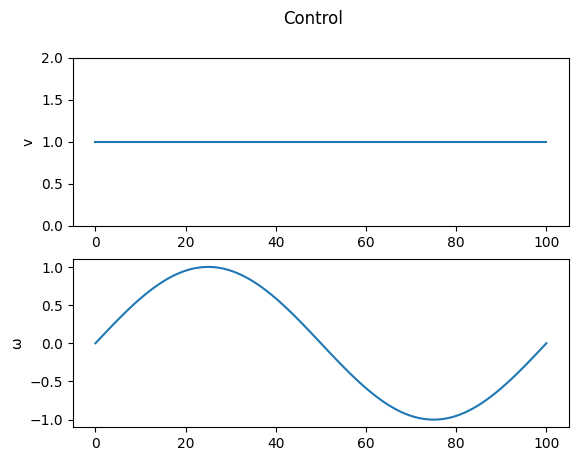

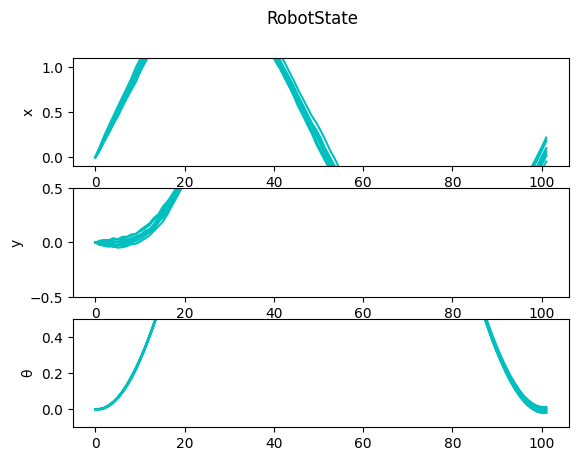

In [20]:
# Constants
num_rollouts = 10
num_steps = 100

# Define the dynamics class
dynamics = RobotDynamics()

# Define the control inputs
u_sequence = np.ones((dynamics.m, num_steps))
u_sequence[1,:] = np.sin(np.linspace(0, 2 * np.pi, num_steps))

# Define inital state
x0 = np.array([0, 0, 0])

# Rollouts dynamics
rollouts = dynamics.rollout(x0, u_sequence, num_rollouts)

# Plot control inputs
fig_ctrl, axs_ctrl = plt.subplots(nrows=dynamics.m)
ylabels_ctrl = ["v", "ω"]
ylims_ctrl = np.array([[0.0, 2.0],[-1.1, 1.1]])
for j in range(dynamics.m):
  axs_ctrl[j].plot(np.linspace(0, num_steps, num_steps), u_sequence[j, :])
  axs_ctrl[j].set_ylabel(ylabels_ctrl[j])
  axs_ctrl[j].set_ylim(ylims_ctrl[j, :])
fig_ctrl.suptitle("Control")

# Plot state trajectory rollouts
fig_state, axs_state = plt.subplots(nrows=dynamics.n)
ylabels_state = ["x", "y", "θ"]
ylims_state = np.array([[-0.1, 1.1], [-0.5, 0.5], [-0.1, 0.5]])
for i in range(num_rollouts):
  for j in range(dynamics.n):
    axs_state[j].plot(np.linspace(0, num_steps + 1, num_steps + 1), rollouts[i, j, :], c='c')
    axs_state[j].set_ylabel(ylabels_state[j])
    axs_state[j].set_ylim(ylims_state[j,:])
fig_state.suptitle("RobotState")
plt.show()